### Q1

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('train_data.csv')
df.head()

C:\Users\alijm\AppData\Local\Temp\ipykernel_28580\2497058397.py:5: DtypeWarning: Columns (1: vote) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('train_data.csv')


,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime
0,2,NaN,False,2016-11-11,A2OSUEZJIN7BI,0511189877,NaN,Chris,I have an older URC-WR7 remote and thought thi...,Cannot Learn,1478822400
1,5,NaN,True,2016-06-06,A2NETQRG6JHIG7,0511189877,NaN,Qrysta White,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?,1465171200
2,4,NaN,True,2016-03-10,A12JHGROAX49G7,0511189877,NaN,Linwood,Got them and only 2 of them worked. company ca...,Works Good and programs easy.,1457568000
3,5,NaN,True,2016-01-14,A1KV65E2TMMG6F,0511189877,NaN,Dane Williams,I got tired of the remote being on the wrong s...,Same as TWC remote,1452729600
4,5,NaN,True,2016-10-20,A280POPEWI0NSA,0594459451,NaN,Kristina H.,After purchasing cheap cords from another webs...,Good Quality Cord,1476921600


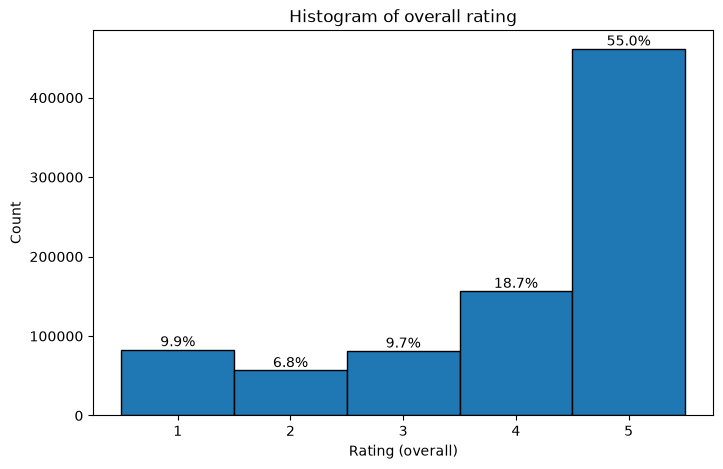

In [2]:
import matplotlib.pyplot as plt

# motevazen hast ya na?
plt.figure(figsize=(8, 5))
counts, bins, patches = plt.hist(
    df['overall'],
    bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
    edgecolor='black'
)

total = counts.sum()
for count, patch in zip(counts, patches):
    percent = count / total * 100
    x = patch.get_x() + patch.get_width() / 2   
    y = patch.get_height()                       
    plt.text(x, y, f'{percent:.1f}%', ha='center', va='bottom')

plt.xticks([1, 2, 3, 4, 5])
plt.xlabel('Rating (overall)')
plt.ylabel('Count')
plt.title('Histogram of overall rating')
plt.show()

 آیا مجموعه‌داده متوازن است؟در دیتاست‌های نظرات آمازون تقریباً همیشه توزیع به شدت نامتوازن است: امتیاز ۵ (و بعد ۴) سهم غالب رو دارند و امتیازهای ۲ و ۳ کمترین تعداد رو. پس پاسخ خیر است

آیا متوازن‌سازی لازم است؟ بله

برای مدل‌سازی باید با این نامتوازنی کاری کرد، چون مدل به سمت کلاس اکثریت سوگیری پیدا می‌کنه

بهترین راه undersampling است 

چون اول هزینه اموزش رو کمتر میکنه و میشه با تعداد نظراتی کمتری اموزش داد برای همچین دیتاست های بزرگی

### Q2

In [3]:
%pip install nltk wordcloud

Note: you may need to restart the kernel to use updated packages.


In [4]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading wordnet: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be

False

[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading wordnet: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be

sentiment
positive    617999
negative    139706
neutral      81239
Name: count, dtype: int64


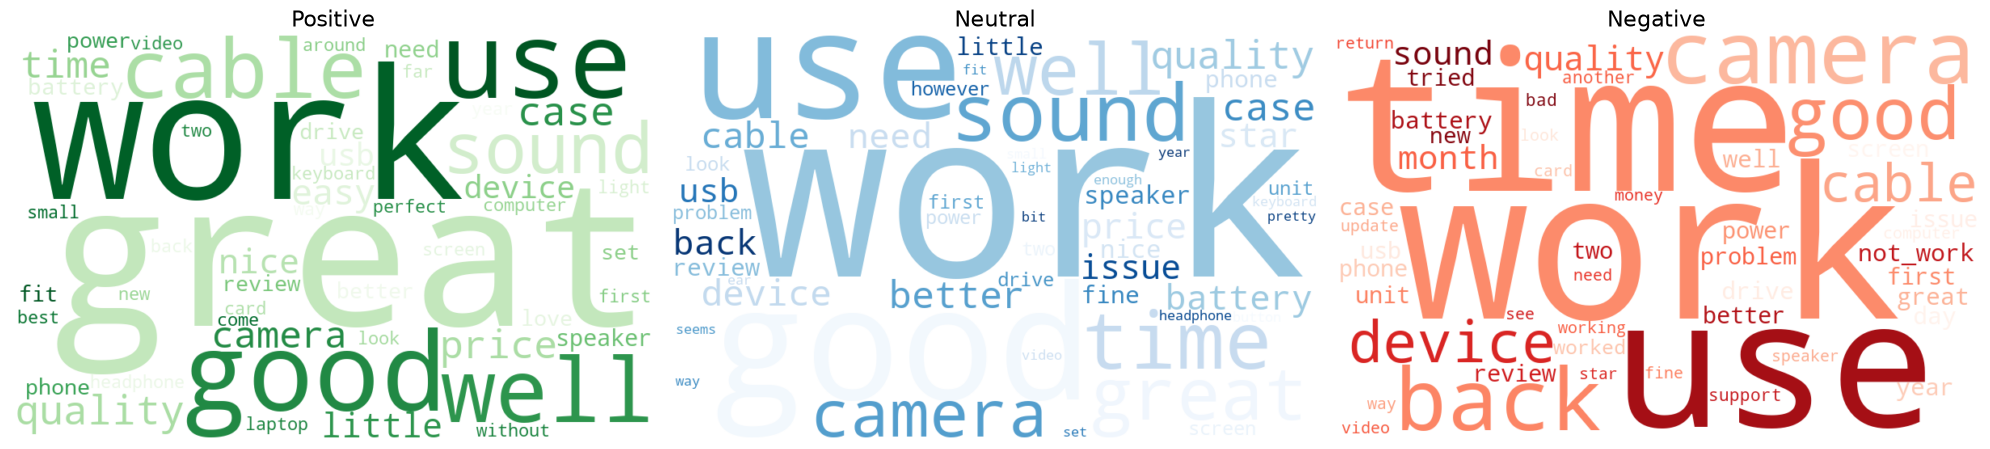

Common words in top 50: 32
['back', 'battery', 'better', 'cable', 'camera', 'card', 'case', 'computer', 'device', 'drive', 'first', 'good', 'great', 'look', 'need', 'new', 'phone', 'power', 'quality', 'review', 'screen', 'sound', 'speaker', 'time', 'two', 'usb', 'use', 'video', 'way', 'well', 'work', 'year']


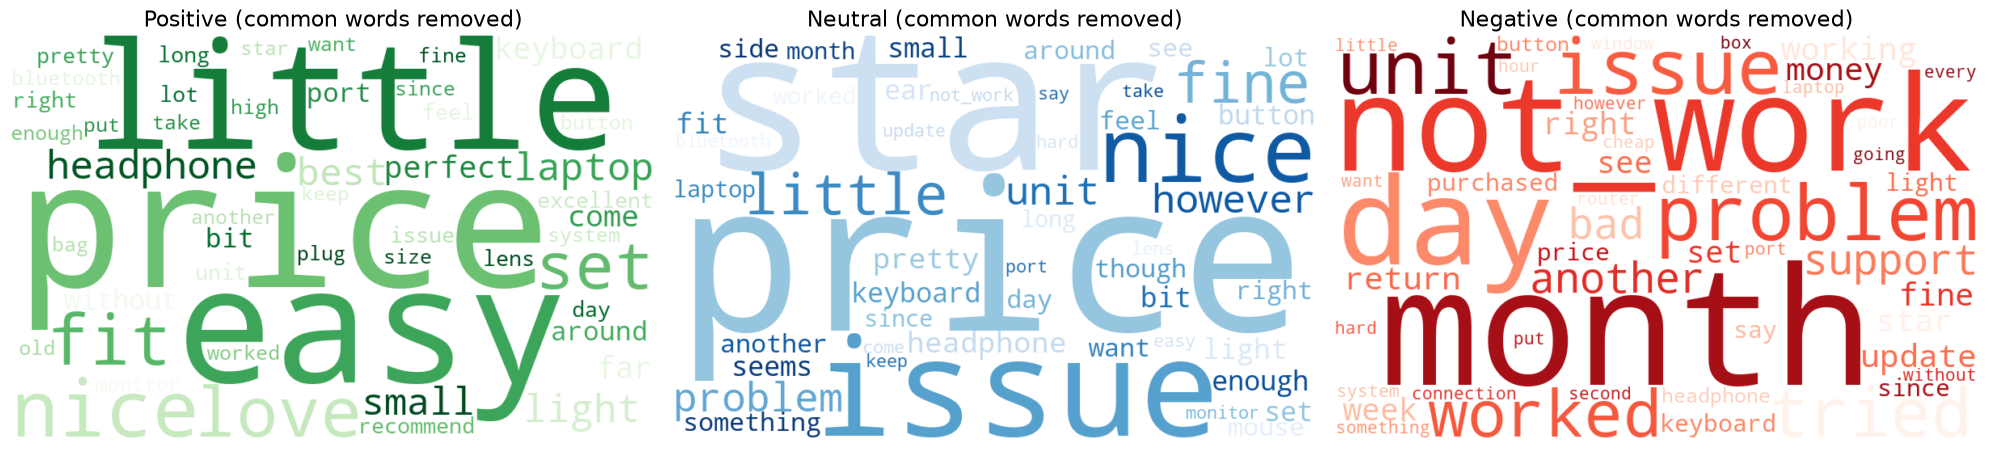

In [5]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from collections import Counter
from functools import lru_cache
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud

nltk.download('stopwords')
nltk.download('wordnet')

SEED = 42
SAMPLE_PER_SENTIMENT = 20_000

df = df.dropna(subset=['overall']).copy()
df['overall'] = df['overall'].astype(int)

def to_sentiment(r):
    if r >= 4:
        return 'positive'
    if r == 3:
        return 'neutral'
    return 'negative'

df['sentiment'] = df['overall'].apply(to_sentiment)
print(df['sentiment'].value_counts())

df['text'] = df['summary'].fillna('') + ' ' + df['reviewText'].fillna('')

# نفی‌ها و کلمات احساسی حفظ می‌شن 
NEG = {'not', 'no', 'nor', 'never'}
STOP = set(stopwords.words('english')) - NEG
STOP |= {'one', 'would', 'get', 'got', 'also', 'used', 'using', 'really',
         'much', 'even', 'will', 'could', 'still', 'make', 'made', 'bought',
         'buy', 'product', 'item', 'amazon', 'thing', 'just', 'like',
         'quot', 'amp', 'nbsp'}

lemm = WordNetLemmatizer()

@lru_cache(maxsize=None)
def lemma(w):
    return lemm.lemmatize(w)

def clean_text(text):
    text = str(text).lower().replace("’", "'")
    text = re.sub(r"http\S+|&\w+;|<[^>]+>", " ", text)
    text = text.replace("won't", "will not").replace("can't", "can not")
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"[^a-z\s]", " ", text)

    tokens, negate = [], False
    for w in text.split():
        if w in NEG:
            negate = True
            continue
        if w in STOP or len(w) < 3:
            continue
        w = lemma(w)
        if negate:
            w = 'not_' + w
            negate = False
        tokens.append(w)
    return tokens

# شمارش کلمات هر دسته
order = ['positive', 'neutral', 'negative']
counters = {}
for s in order:
    sub = df[df['sentiment'] == s]
    sub = sub.sample(min(len(sub), SAMPLE_PER_SENTIMENT), random_state=SEED)
    c = Counter()
    for t in sub['text']:
        c.update(clean_text(t))
    counters[s] = c

# ابر کلمات هر دسته 
cmaps = {'positive': 'Greens', 'neutral': 'Blues', 'negative': 'Reds'}
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, s in zip(axes, order):
    wc = WordCloud(width=800, height=500, background_color='white',
                   colormap=cmaps[s], max_words=50, prefer_horizontal=1.0,
                   min_font_size=12, relative_scaling=0.4
                   ).generate_from_frequencies(counters[s])
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(s.capitalize(), fontsize=16)
    ax.axis('off')
plt.tight_layout()
plt.show()

# کلمات مشترک مثبت و منفی 
TOP_N = 50
top = {s: {w for w, _ in counters[s].most_common(TOP_N)} for s in order}
common = sorted(top['positive'] & top['negative'])
print(f'Common words in top {TOP_N}: {len(common)}')
print(common)

# حذف کلمات مشترک و رسم ورد کلاد جدید
common_set = set(common)

filtered_counters = {
    s: Counter({w: c for w, c in counters[s].items() if w not in common_set})
    for s in order
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, s in zip(axes, order):
    wc = WordCloud(width=800, height=500, background_color='white',
                   colormap=cmaps[s], max_words=50, prefer_horizontal=1.0,
                   min_font_size=12, relative_scaling=0.4
                   ).generate_from_frequencies(filtered_counters[s])
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'{s.capitalize()} (common words removed)', fontsize=16)
    ax.axis('off')
plt.tight_layout()
plt.show()

معمولاً کلمات مشترک زیادی بین مثبت و منفی دیده می‌شه، مثل نام محصولات و دسته‌ها

این کلمات اکثرا راجب موضوع صحبت میکنند نه احساسات

کلمات احساسی مشترک هم میتونه وجود داشته باشد چون تو نظرات خنثی ممکنه یه سری جیزا خوب و بعضی چیزا بد باشند

### Q3

     reviewerName  total_votes  n_reviews
1    Benson Leung         4572         29
2      Voltron00x         3181          9
3         Obi Wan         3150         29
4          nycebo         2978          2
5        Mayra S.         2631         19
6         Cthulhu         2607         32
7     Chris Upton         2167          5
8        Sally B.         1912          5
9              DJ         1867         24
10  Mark A. Baker         1820          1


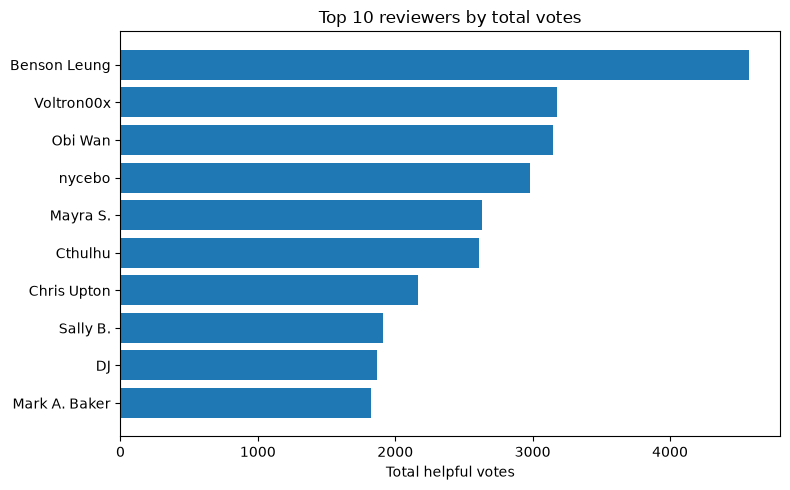

In [6]:
import pandas as pd

# درست کردن رای ها
df['vote_num'] = (df['vote'].astype(str)
                  .str.replace(',', '', regex=False)
                  .pipe(pd.to_numeric, errors='coerce')
                  .fillna(0))

# گروه‌بندی بر اساس reviewerID
top10 = (df.groupby('reviewerID')
           .agg(reviewerName=('reviewerName', 'first'),
                total_votes=('vote_num', 'sum'),
                n_reviews=('reviewerID', 'size'))
           .sort_values('total_votes', ascending=False)
           .head(10)
           .reset_index())

top10['total_votes'] = top10['total_votes'].astype(int)
top10.index = top10.index + 1          # رتبه‌ی ۱ تا ۱۰
print(top10[['reviewerName', 'total_votes', 'n_reviews']])

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.barh(top10['reviewerName'].fillna('Unknown')[::-1], top10['total_votes'][::-1])
plt.xlabel('Total helpful votes')
plt.title('Top 10 reviewers by total votes')
plt.tight_layout()
plt.show()

<a href="https://colab.research.google.com/github/aminrafi394/ai-second-project/blob/Part_One_3_4_5/Part_One_4_5_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**در این بخش کتبخانه های مورد نیاز را وارد می کنیم**

In [151]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


**در این بخش شروع به خواندن داده ها می کنیم**

In [152]:
from google.colab import drive


drive.mount('/content/drive')
path_train = '/content/drive/MyDrive/train_data.csv'
train_data = pd.read_csv(path_train)

path_test = '/content/drive/MyDrive/test_data.csv'
test_data = pd.read_csv(path_test)

title_barnd_path = '/content/drive/MyDrive/title_brand.csv'
title_brand = pd.read_csv(title_barnd_path)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_1118/3381803631.py:6: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  train_data = pd.read_csv(path_train)


In [153]:
train_data.head(10)

,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime
0,2,NaN,False,2016-11-11,A2OSUEZJIN7BI,0511189877,NaN,Chris,I have an older URC-WR7 remote and thought thi...,Cannot Learn,1478822400
1,5,NaN,True,2016-06-06,A2NETQRG6JHIG7,0511189877,NaN,Qrysta White,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?,1465171200
2,4,NaN,True,2016-03-10,A12JHGROAX49G7,0511189877,NaN,Linwood,Got them and only 2 of them worked. company ca...,Works Good and programs easy.,1457568000
3,5,NaN,True,2016-01-14,A1KV65E2TMMG6F,0511189877,NaN,Dane Williams,I got tired of the remote being on the wrong s...,Same as TWC remote,1452729600
4,5,NaN,True,2016-10-20,A280POPEWI0NSA,0594459451,NaN,Kristina H.,After purchasing cheap cords from another webs...,Good Quality Cord,1476921600
5,5,NaN,True,2016-06-18,A2KTAT1Y3VRVSJ,0594459451,NaN,MnMMom3,This is a great charging cable for the Nook. ...,Better than original charger!,1466208000
6,5,NaN,True,2016-02-11,A1CHTT6E3NV5YL,0594459451,NaN,Amazon Shopper,The 90 degree connector is a bonus that allows...,Works great on my Wife's older model Nook Color.,1455148800
7,2,NaN,True,2016-04-02,A1TI6WQ69ST707,0594481902,NaN,kyle,I bought this thinking it would be a great rep...,Good enough to charge and wipe an older nook b...,1459555200
8,4,NaN,True,2016-01-10,A38NYFVE0FCZRG,0594481902,NaN,S. Artist,It works! I was skeptical about ordering it b...,"It works, but it costs $30! Generic USB wall ...",1452384000
9,5,NaN,True,2016-09-19,A2LLAAYS88V96P,0594296420,NaN,Tabatha,Brand name adapter this is just like the one y...,Brand name adapter this is just like the one y...,1474243200


In [154]:
test_data.head(10)

,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime
0,NaN,True,2018-06-04,A20GGWE66JW9X2,B006Z394GM,{'Color:': ' FPS01-C'},Brian C Toner,The name and description of this device are mi...,The prize for most useless invention of all ti...,1528070400
1,NaN,True,2018-02-18,ARYJWXHEYHG9M,B005BE058W,"{'Size:': ' 1000W', 'Style:': ' G2'}",Snake,One of the molex connectors on the power suppl...,MELTED MOLEX CONNECTOR,1518912000
2,NaN,True,2018-01-20,A10LHZ7WFZ7HLL,B01DA0YCNC,NaN,Amazon Customer,Remote constantly disconnects/ Roku player fre...,Bricked on the regular,1516406400
3,NaN,True,2018-06-25,A11VN8EOHNLP72,B00FBJ4KYC,NaN,Jeremy Bray,I purchased this 4 year protection plan for a ...,DO NOT BUY!!!,1529884800
4,3.0,True,2016-08-17,A194Y8P8TVT7P9,B00P7G82TS,NaN,Mark,I bought one of these and have regretted it ev...,Nightmare - don't buy,1471392000
5,NaN,True,2017-09-15,ACZDN5A7ZH6RM,B006FKAZ36,{'Size:': ' 100 Feet'},Dj Breaz,Item came in with good timing. I went to use t...,Good Feel But Did Not Work.,1505433600
6,NaN,True,2016-06-27,A3K4C1O8X5HCQQ,B00KHRSGO8,{'Color:': ' White'},jachansen,I'm returning mine. I used the VGA port to go ...,Maybe you'll have better luck,1466985600
7,NaN,True,2016-10-31,AACVNY9PBN3VN,B01DOB6YW4,NaN,Sahil P,"It claims to be 128GB, Only Reads 119GB. Fake ...",Very Sad.,1477872000
8,NaN,True,2016-07-07,A3Q1AR7PVTFRSM,B01CZPJRW4,NaN,Bigbillyt,"These cables are the wrong thing, the 4 pin mo...","Sorry, I incorrectly mixed up my review for a ...",1467849600
9,2.0,True,2016-03-14,A2ZW2AF10TCKR1,B00I0FI838,{'Size:': ' 6 x 9 Inches'},Craig&#039;s Garage,"Smaller magnet than many similar products, poo...",Cheap budget speakers with poor mounting hardw...,1457913600


In [155]:
title_brand.head(10)

,asin,title,brand
0,0011300000,Genuine Geovision 1 Channel 3rd Party NVR IP S...,GeoVision
1,0043396828,"Books ""Handbook of Astronomical Image Processi...",33 Books Co.
2,0060009810,One Hot Summer,Visit Amazon's Carolina Garcia Aguilera Page
3,0060219602,Hurray for Hattie Rabbit: Story and pictures (...,Visit Amazon's Dick Gackenbach Page
4,0060786817,sex.lies.murder.fame.: A Novel,Visit Amazon's Lolita Files Page
5,0070524076,College Physics,Visit Amazon's Alan Giambattista Page
6,0091912407,Girl with a One-track Mind: Confessions of the...,ABBY LEE
7,0101635370,abcGoodefg&reg; 4GB USB 2.0 Mp3 Music Player w...,Crazy Cart
8,0132492776,Wireless Bluetooth Headphones Earbuds with Mic...,Enter The Arena
9,0132793040,Kelby Training DVD: Mastering Blend Modes in A...,Kelby Training


# Q 4

In [156]:
copy_train = train_data.copy()

**در این بخش یک ستون جدید ستون جدید ایجاد شده که با استفاده از آن تعداد واژه های درون هر پیام مشخص بشود  
سپس در مرحله بعد با حذف داده هایی که پر نشده اند و با استفاده از چارک ها یک ماسک بولی ساخته می شود تا داده های پرت در نظر گرفته نشوند**

In [157]:
target_column = copy_train[["reviewText"]]
target_column["reviewTextLength"] = copy_train["reviewText"].agg(
    lambda x : len(list(x.split(" ")))
)
target_column

/tmp/ipykernel_1118/4166783402.py:2: FutureWarning: using <function <lambda> at 0x77fcfa169440> in Series.agg cannot aggregate and has been deprecated. Use Series.transform to keep behavior unchanged.
  target_column["reviewTextLength"] = copy_train["reviewText"].agg(
/tmp/ipykernel_1118/4166783402.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  target_column["reviewTextLength"] = copy_train["reviewText"].agg(


,reviewText,reviewTextLength
0,I have an older URC-WR7 remote and thought thi...,113
1,First time I've EVER had a remote that needed ...,89
2,Got them and only 2 of them worked. company ca...,42
3,I got tired of the remote being on the wrong s...,62
4,After purchasing cheap cords from another webs...,49
...,...,...
838939,These are my favorite charging cords for a few...,51
838940,"Update....after 2 months of gentle use, cable ...",37
838941,These are okay. The connection becomes very if...,42
838942,"Ok here is an odd thing that happened to me, I...",111


In [158]:
before_procces_lines: int = len(target_column)

target_column = target_column.dropna()

after_remove_line: int = len(target_column)

print(f"Removed line {before_procces_lines - after_remove_line}")


Removed line 0


**در این بخش نمودار هستوگرام داده های طول نظرات به صورت طبیعی و بدون در نظر گرفتن داده های پرت و دارای تعداد کم رسم می شود در این حالت برای مشخص کردن تعداد ستون های بهینه با استفاده از حلقه تعداد از ۲۰ تا ۵۰ در نظر گرفته می شود**

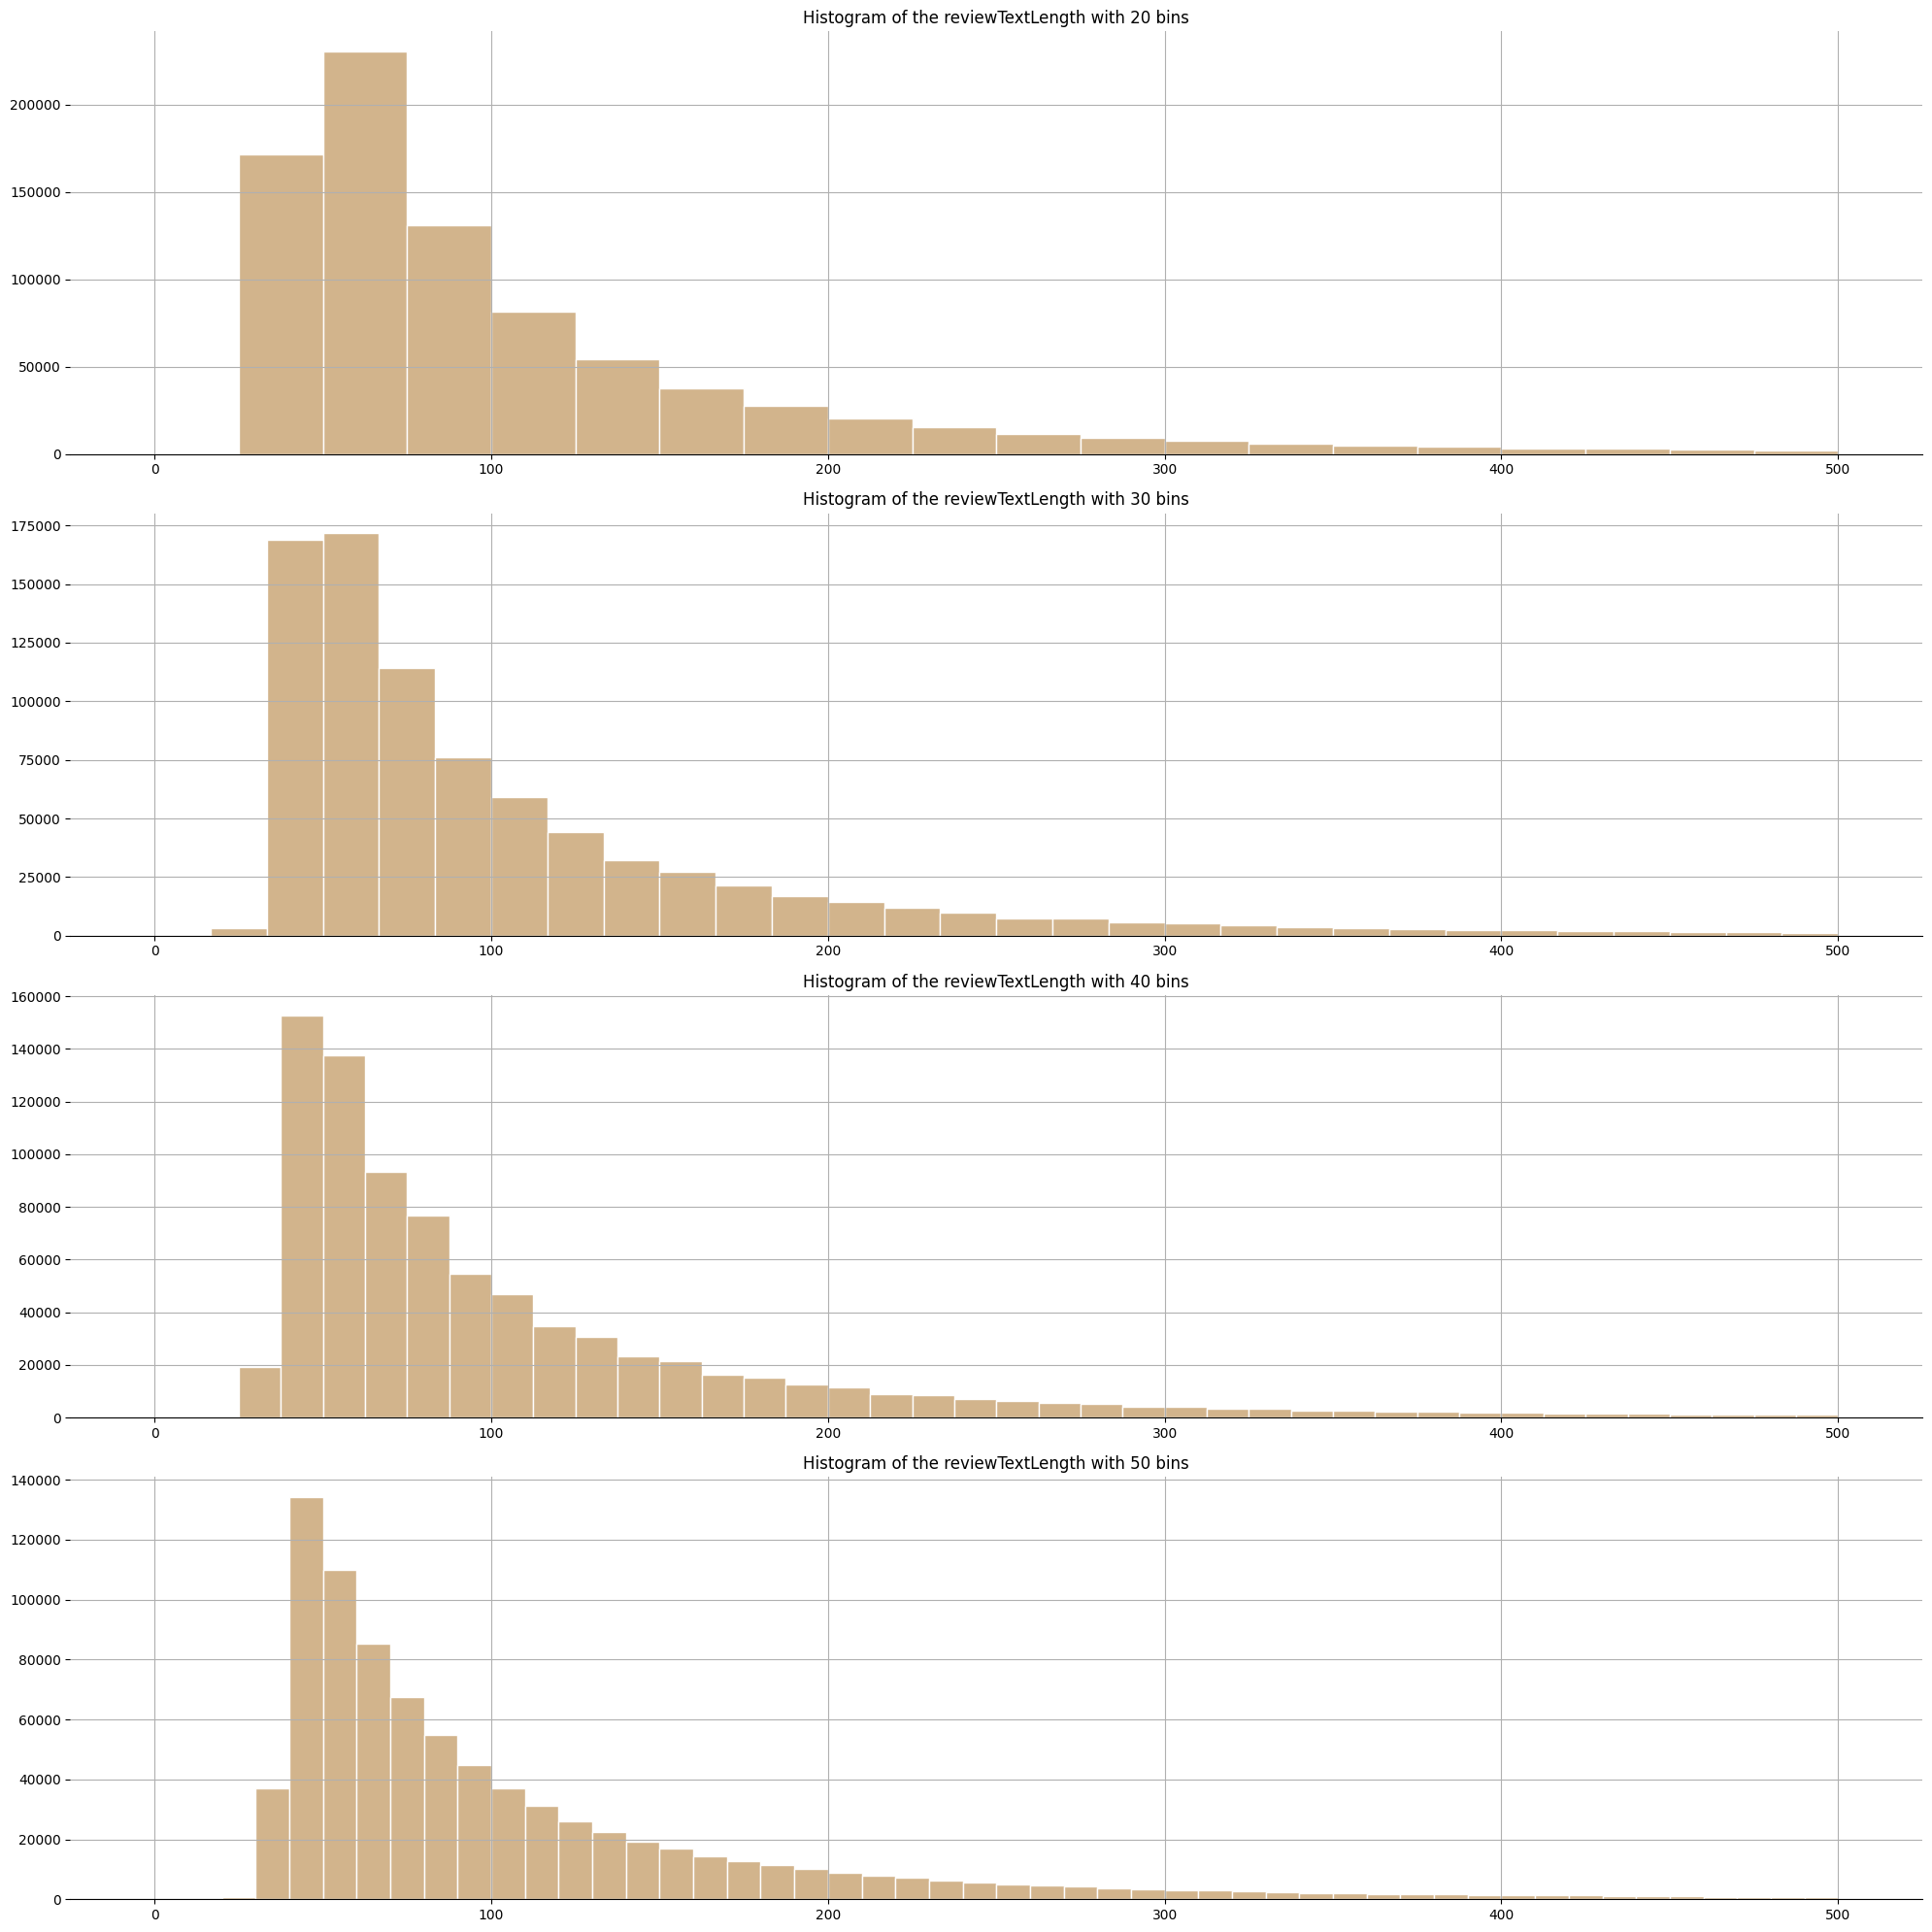

In [159]:
figure, axes = plt.subplots(4, 1, figsize=(20, 20))

flattern_axes = axes.flatten()

for ax, bin_count in zip(flattern_axes, [20, 30, 40, 50]):
  ax.spines["top"].set_visible(False)
  ax.spines["left"].set_visible(False)
  ax.spines["right"].set_visible(False)

  ax.hist(target_column["reviewTextLength"], bins=bin_count, edgecolor="white", color="tan", range=(0, 500))
  ax.set_title(f"Histogram of the reviewTextLength with {bin_count} bins")
  ax.grid()

plt.tight_layout()



In [160]:
from sklearn.preprocessing import FunctionTransformer

before_procces_lines: int = len(target_column)

def remove_length_outliers(data_frame: pd.DataFrame):
  quantile_first: int = data_frame["reviewTextLength"].quantile(0.25)
  quantile_second: int = data_frame["reviewTextLength"].quantile(0.75)

  data_frame = data_frame[(data_frame["reviewTextLength"] >= quantile_first) & (data_frame["reviewTextLength"] <= quantile_second)]

  return data_frame

remover_length = FunctionTransformer(remove_length_outliers)
target_column = remover_length.transform(target_column)

after_remove_line: int = len(target_column)

print(f"Removed line {before_procces_lines - after_remove_line} as outliers")
target_column

Removed line 416801 as outliers


,reviewText,reviewTextLength
0,I have an older URC-WR7 remote and thought thi...,113
1,First time I've EVER had a remote that needed ...,89
3,I got tired of the remote being on the wrong s...,62
5,This is a great charging cable for the Nook. ...,57
8,It works! I was skeptical about ordering it b...,128
...,...,...
838934,Some other buyers complained about not having ...,75
838936,EDIT: because the N1 is no longer offered by V...,76
838938,Fits the old cordless phones just fine and wor...,80
838942,"Ok here is an odd thing that happened to me, I...",111


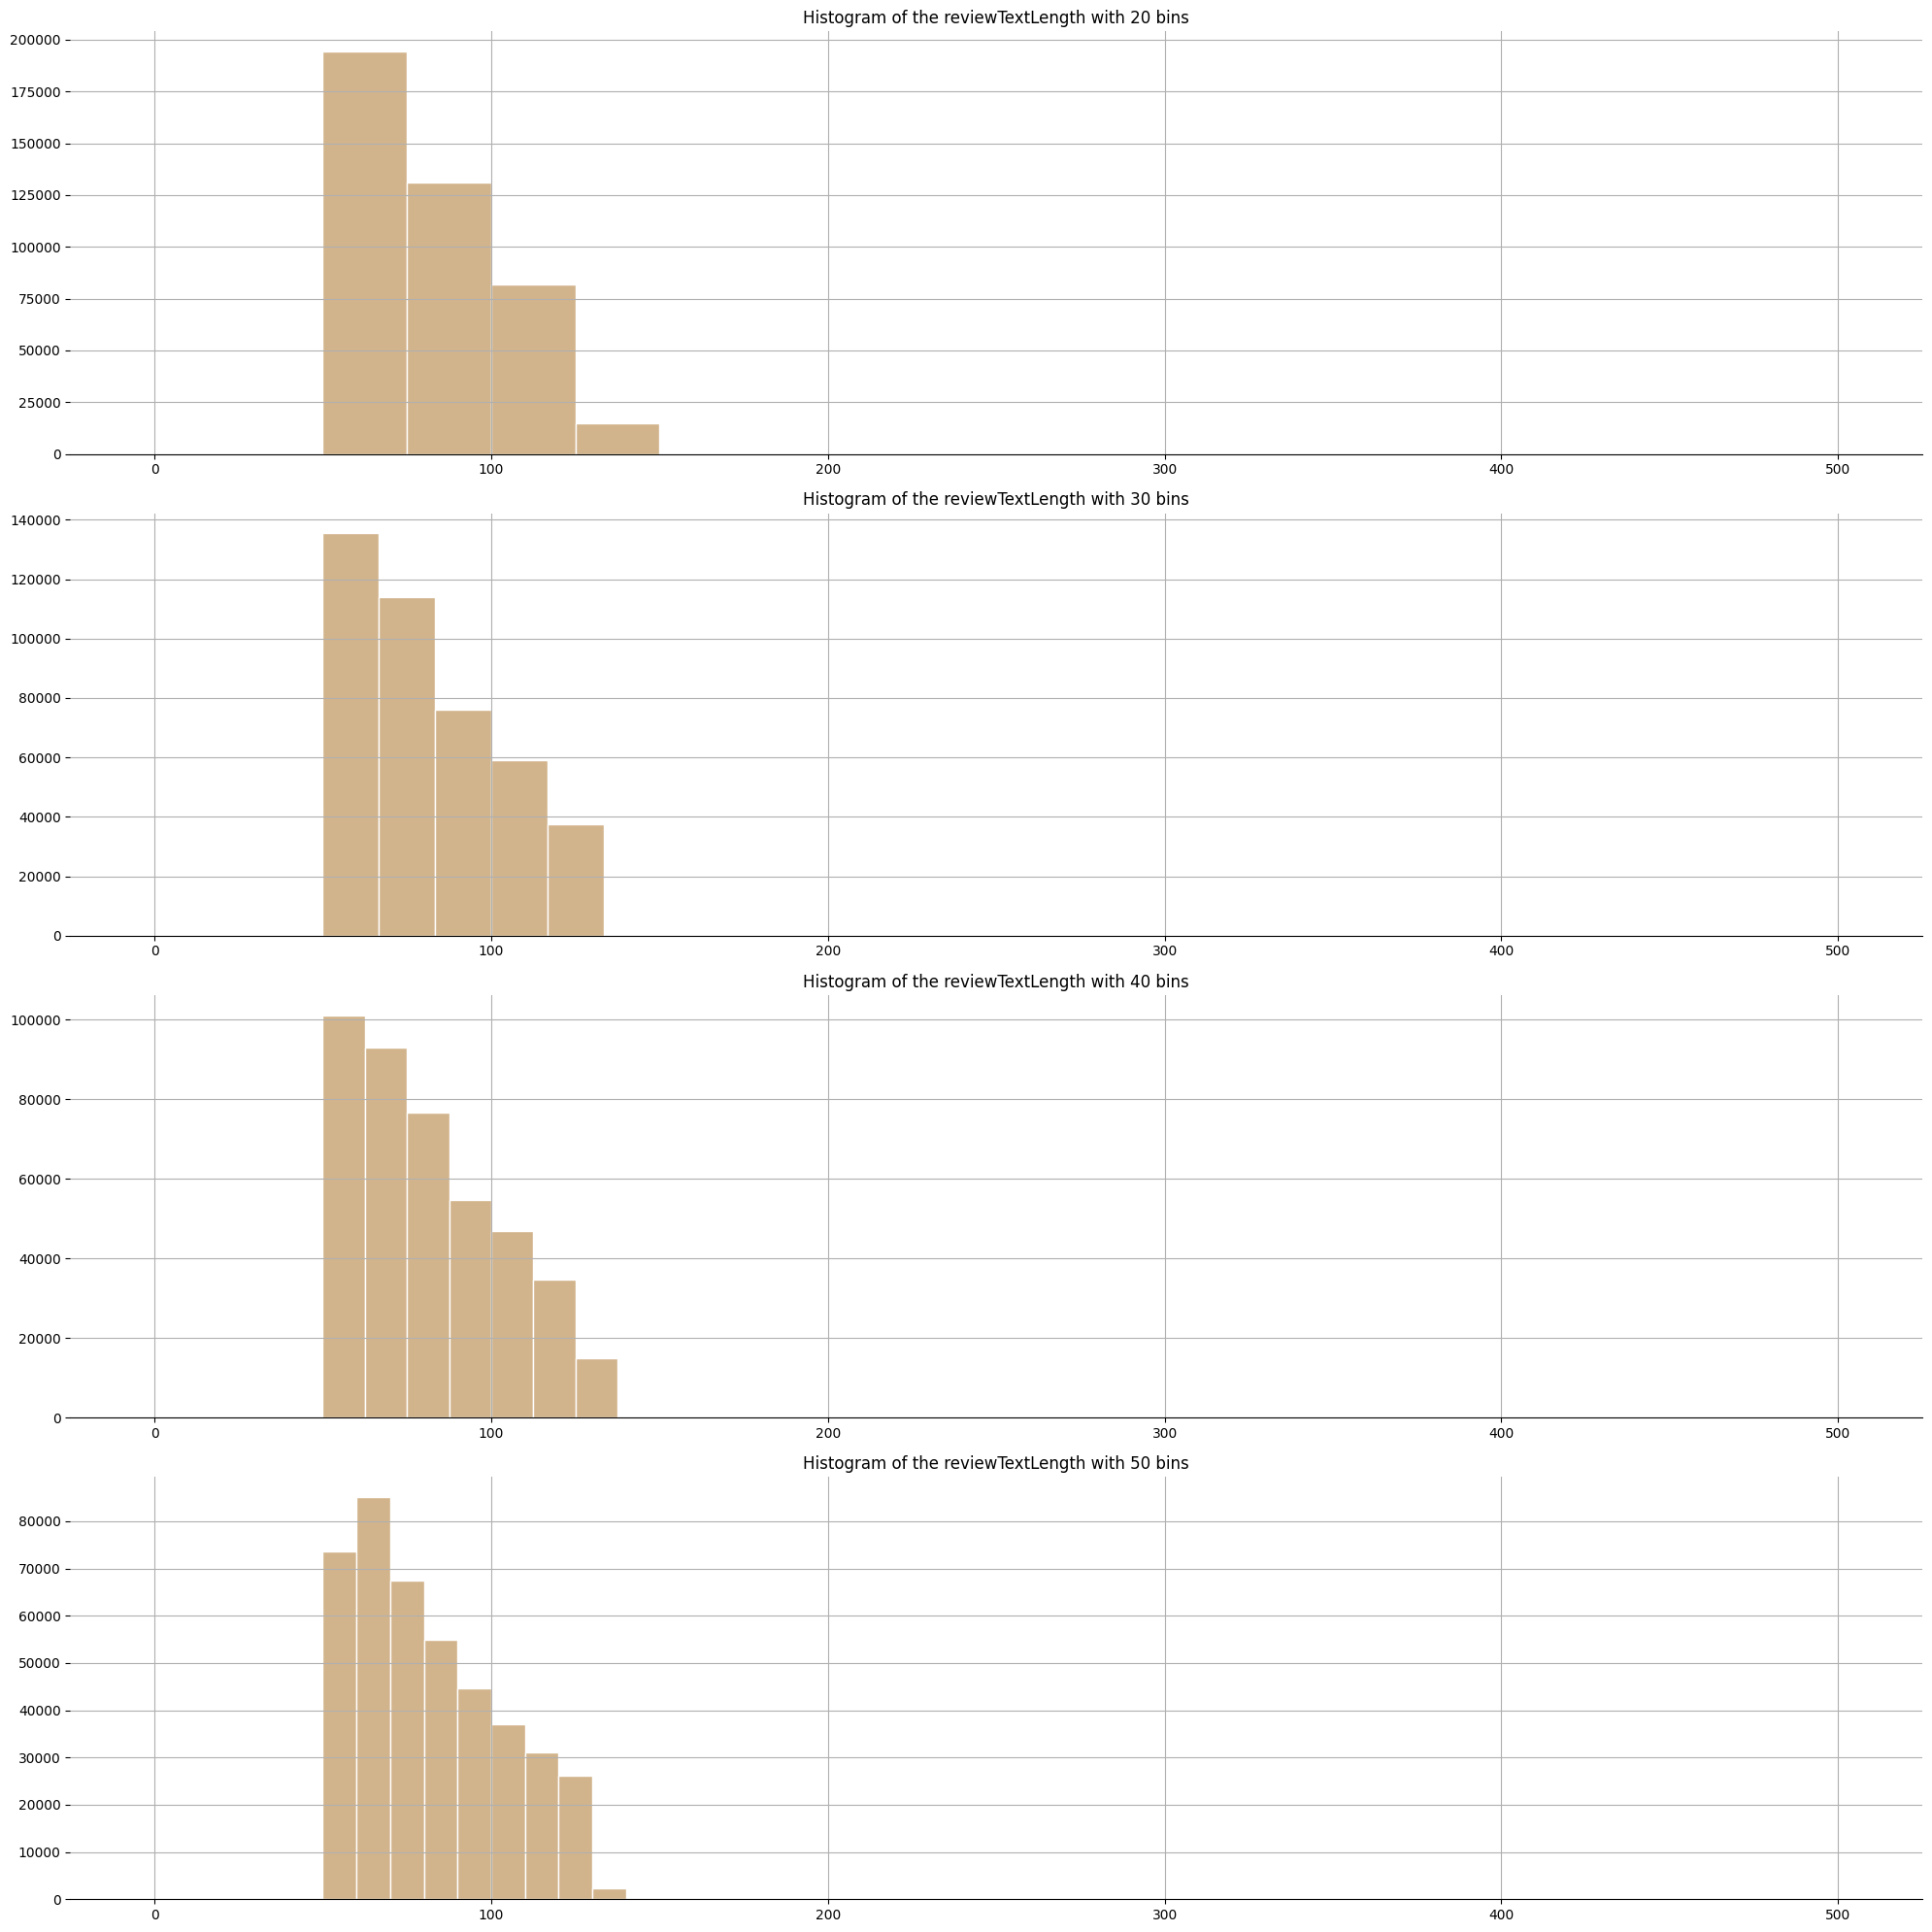

In [161]:
figure, axes = plt.subplots(4, 1, figsize=(20, 20))

flattern_axes = axes.flatten()

for ax, bin_count in zip(flattern_axes, [20, 30, 40, 50]):
  ax.spines["top"].set_visible(False)
  ax.spines["left"].set_visible(False)
  ax.spines["right"].set_visible(False)

  ax.hist(target_column["reviewTextLength"], bins=bin_count, edgecolor="white", color="tan", range=(0, 500))
  ax.set_title(f"Histogram of the reviewTextLength with {bin_count} bins")
  ax.grid()

plt.tight_layout()



**مشاهده می شود که در بین داده ها  
پیش از زمان خذف داده های پرت تعداد واژه های نظرات به بیش از ۴۰۰ و ۵۰۰ می رسید و نمودار یه چولگی بسیار بدی داشت  و تجمع اکثریت در بین داده های بین مثلا ۵۰ تا ۲۰۰ بود بنابرین طبق نمودار ها رسم شده برای خونایی بهتر تعداد ستون ها به ۴۰ و تعداد این بازه از ۵۰ تا ۲۰۰ انتخاب می شود تا داده های موثر و تراکم بالا در نظر گرفته بشوند.**

# Q 5

**در این بخش ابتدا از داده یک کپی می گیریم. سپس داده های با امتیاز ۵ را جداسازی کرده و با استفاده از تابع شمارش برداشته و در نهایت حواب تحویل داده می شود**

In [162]:
copy_data = train_data.copy()


In [163]:
copy_data.dtypes

,0
overall,int64
vote,object
verified,bool
reviewTime,object
reviewerID,object
asin,object
style,object
reviewerName,object
reviewText,object
summary,object


In [164]:
copy_data = copy_data.dropna()

In [165]:
copy_data = copy_data[copy_data["overall"] == 5]

copy_data

,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime
18,5,4.0,True,2017-02-18,A1JHNR71TPEETW,073530498X,{'Format:': ' Spiral-bound'},Amazon Customer,I bought this to display some vintage photos t...,Great way to showcase vintage photos!,1487376000
19,5,2.0,True,2016-12-26,AU7SO8B4M5UBA,073530498X,{'Format:': ' Spiral-bound'},ruth,Cute! Bought 2 for my daughter. I thought it w...,They are nice.,1482710400
45,5,10.0,True,2016-03-26,AHQ63IBAOCUC6,1059844575,{'Color:': ' Black'},javibarr,I had given this item a 1 star and bad review ...,If you want it to work properly Read This!!,1458950400
46,5,4.0,True,2016-03-17,A21JOU9DTCR6WS,1059844575,{'Color:': ' Black'},Daniel Baker,Works just fine for LG G4.\nI think it should ...,Works just fine for LG G4.,1458172800
67,5,2.0,True,2016-02-10,AXLHMG77HZ7BJ,1464120153,{'Format:': ' Misc. Supplies'},Anthony megalizzi,I needed this iClicker for a college class and...,... iClicker for a college class and it works ...,1455062400
...,...,...,...,...,...,...,...,...,...,...,...
838612,5,3.0,True,2017-04-27,A2NLL1FJFW8HBF,B01HDXX3MS,{'Color:': ' Pink with Polkadots'},Miranda,"Great design. Pretty loud. Not too bulky, and ...",Great design. Pretty loud,1493251200
838643,5,3.0,True,2018-02-01,A1PO7VBPAVGM1N,B01HEF8OV0,{'Capacity:': ' 10TB'},heraldo,10TB model review. HGST are makers of the best...,Super reliable! Quiet enough for me.,1517443200
838667,5,2.0,True,2018-05-03,A2D4WD6GRBHZ2E,B01HEQJGRU,{'Color:': ' Silver'},beatcomber,I purchased this specifically for doing vinyl ...,Great for impedance matching the record output...,1525305600
838797,5,2.0,False,2016-07-31,A1LFQEQNMBWRZ2,B01HGKPJJ8,{'Color:': ' Charcoal'},The Organic Millennial,The problem Ive been having is finding a way t...,Solution to stick your phone anwhere!,1469923200


In [166]:
target_frame = copy_data.copy()
target_frame = target_frame.groupby(["asin"]).size()
target_frame = target_frame.sort_values(ascending=False)
target_frame = target_frame.head(10)

target_frame

,0
asin,
B00S9SGNNS,105
B01A7G35S0,101
B009ZGK6QS,95
B003Y5RYNY,86
B01DUTOI5U,86
B00Y01VRSO,83
B01E3SNO3E,81
B01DXVKQEW,75
B00LV8YZLK,69


 حال یا استفاده از داده های brand داده های مطلوب را به دست می آوریم

In [167]:
target_frame = target_frame.reset_index()

target_frame = target_frame.rename(columns={0 : "Total_votes"})

target_frame

,asin,Total_votes
0,B00S9SGNNS,105
1,B01A7G35S0,101
2,B009ZGK6QS,95
3,B003Y5RYNY,86
4,B01DUTOI5U,86
5,B00Y01VRSO,83
6,B01E3SNO3E,81
7,B01DXVKQEW,75
8,B00LV8YZLK,69
9,B00V49LNCU,68


In [168]:
target_asins = target_frame['asin'].unique()
filtered_df = title_brand[title_brand['asin'].isin(target_asins)]


In [169]:
merged_df = pd.merge(filtered_df, target_frame, on='asin', how='inner')

In [170]:
merged_df = merged_df.sort_values(by=["Total_votes"], ascending=False)
merged_df = merged_df.reset_index

In [171]:
merged_df


<bound method DataFrame.reset_index of          asin                                              title  \
3  B00S9SGNNS  ASUS Tri-Band Gigabit (AC3200) WiFi Router (Up...   
6  B01A7G35S0  1MORE Triple Driver In-Ear Earphones Hi-Res He...   
1  B009ZGK6QS  BAFX Products IR Remote Control Extender/IR Re...   
0  B003Y5RYNY  TP-Link N450 Wi-Fi Router - Wireless Internet ...   
7  B01DUTOI5U  Samsung UN40KU6300 40-Inch 4K Ultra HD Smart L...   
5  B00Y01VRSO  eero Home WiFi System (Individual) - 1st Gener...   
9  B01E3SNO3E  Bose QuietComfort 35 (Series I) Wireless Headp...   
8  B01DXVKQEW  Samsung Galaxy Tab S2 8&quot;; 32 GB Wifi Tabl...   
2  B00LV8YZLK              Ubiquiti Unifi Security Gateway (USG)   
4  B00V49LNCU  Samsung Galaxy Tab A 8&quot;; 16 GB Wifi Table...   

               brand  Total_votes  
3               Asus          105  
6              1MORE          101  
1      BAFX Products           95  
0            TP-LINK           86  
7            Samsung           86  
5               eero           83  
9               Bose           81  
8            Samsung           75  
2  Ubiquiti Networks           69  
4            Samsung           68  >

# Q 6

**در اولین مرتبه یه کپی از داده های گرفته میشه**

In [199]:
copy_data = train_data.copy()

In [200]:
copy_data = copy_data.dropna()

In [201]:
copy_data = copy_data.groupby(["asin"]).agg(
    {
      "overall" : "mean",
      "vote" : "size"
    }
)
copy_data = copy_data.reset_index()

In [202]:
copy_data

,asin,overall,vote
0,073530498X,5.000000,2
1,1059844575,5.000000,2
2,1444700650,1.000000,1
3,1464120153,4.000000,2
4,1495443043,3.000000,1
...,...,...,...
19418,B01HIS5N3K,3.461538,13
19419,B01HIS5O7A,4.500000,2
19420,B01HIWBNOY,1.000000,1
19421,B01HIWPMNW,5.000000,1


In [203]:
copy_data = copy_data.rename(columns={0 : "total_votes"})
copy_data

,asin,overall,vote
0,073530498X,5.000000,2
1,1059844575,5.000000,2
2,1444700650,1.000000,1
3,1464120153,4.000000,2
4,1495443043,3.000000,1
...,...,...,...
19418,B01HIS5N3K,3.461538,13
19419,B01HIS5O7A,4.500000,2
19420,B01HIWBNOY,1.000000,1
19421,B01HIWPMNW,5.000000,1


In [204]:
target_asins = copy_data['asin'].unique()
filtered_df = title_brand[title_brand['asin'].isin(target_asins)]


In [205]:
merged_df = pd.merge(filtered_df, copy_data, on='asin', how='inner')

In [206]:
merged_df

,asin,title,brand,overall,vote
0,073530498X,Vintage Camera Photo Album,Visit Amazon's Galison Page,5.000000,2
1,1059844575,SlimPort sli44532 Adapter for LG G3 Smartphone...,SlimPort,5.000000,2
2,1444700650,Nightfall,Visit Amazon's Stephen Leather Page,1.000000,1
3,1464120153,Iclicker+ Student Remote,i-clicker,4.000000,2
4,1495443043,Country Heaven (Dare River),Visit Amazon's Ava Miles Page,3.000000,1
...,...,...,...,...,...
19883,B01HIS5N3K,JAM Rhythm WiFi Home Audio Speaker with Amazon...,Jam,3.461538,13
19884,B01HIS5O7A,Polk Audio BITB-A Boom Bit Black,Polk BOOM,4.500000,2
19885,B01HIWBNOY,"Amtrak Solar Exhuast Fan 12&quot; DC Fan, Most...",Amtrak Solar,1.000000,1
19886,B01HIWPMNW,Galaxy Tab A 7.0 Case by KIQ (TM) Full-Body Sh...,KIQ,5.000000,1


In [207]:
merged_df = merged_df.sort_values(by=["vote"], ascending=False)

In [208]:
merged_df.head(10)

,asin,title,brand,overall,vote
10044,B00S9SGNNS,ASUS Tri-Band Gigabit (AC3200) WiFi Router (Up...,Asus,3.103448,261
9295,B00P7EVST6,Arlo - Wireless Home Security Camera System | ...,"Arlo Technologies, Inc",2.425414,181
11767,B00Y01VRSO,eero Home WiFi System (Individual) - 1st Gener...,eero,3.511364,176
14484,B016F3M7OM,"YI Home Camera, Wi-Fi IP Indoor Security Syste...",YI,3.023392,171
18184,B01E3SNO3E,Bose QuietComfort 35 (Series I) Wireless Headp...,Bose,3.860606,165
18062,B01DUTOI5U,Samsung UN40KU6300 40-Inch 4K Ultra HD Smart L...,Samsung,3.869565,161
16202,B01A7G35S0,1MORE Triple Driver In-Ear Earphones Hi-Res He...,1MORE,4.135484,155
17043,B01C5TFNSM,Samsung UN65KS8000 65-Inch 4K Ultra HD Smart L...,Samsung,3.735714,140
2497,B003Y5RYNY,TP-Link N450 Wi-Fi Router - Wireless Internet ...,TP-LINK,3.985507,138
5619,B00E8HGWIK,TiVo Roamio Pro 3 TB DVR (Old Version) - Digit...,TiVo,3.350746,134


In [209]:
merged_df = merged_df[["brand", "overall"]]
merged_df = merged_df.reset_index()


In [212]:
merged_df = merged_df.drop(columns=["index"])

In [216]:
merged_df.head(10)

,brand,overall
0,Asus,3.103448
1,"Arlo Technologies, Inc",2.425414
2,eero,3.511364
3,YI,3.023392
4,Bose,3.860606
5,Samsung,3.869565
6,1MORE,4.135484
7,Samsung,3.735714
8,TP-LINK,3.985507
9,TiVo,3.350746
